In [ ]:
import torch
import csv
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
    

In [5]:
df = pd.read_csv("dataset/taxis.csv")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [6]:
# Data Preprocessing
df = df.dropna(subset=["pickup_borough","dropoff_borough"])
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

# Duration + remove bad rows
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60
df = df[(df["distance"] > 0) & (df["fare"] > 0) & (df["duration_min"] > 0)]

# Feature extraction
df["hour"] = df["pickup"].dt.hour
df["day_of_week"] = df["pickup"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["is_yellow"] = (df["color"] == "yellow").astype(int)
df["same_borough"] = (df["pickup_borough"] == df["dropoff_borough"]).astype(int)

# X and y
X = pd.get_dummies(
    df[["distance", "duration_min", "hour", "day_of_week", "is_weekend",
        "passengers", "is_yellow", "same_borough",
        "pickup_borough", "dropoff_borough"]],
    columns=["pickup_borough", "dropoff_borough"], dtype=float,
)
y = df["fare"]
print(X.shape, y.shape)



(6347, 17) (6347,)


In [7]:
# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train)
print(y_train)


      distance  duration_min  hour  day_of_week  is_weekend  passengers  \
1343      2.20     21.816667    14            1           0           1   
58        4.50     25.450000    23            4           0           1   
4571      1.69      9.283333    22            2           0           5   
3354      1.70     15.566667     8            3           0           0   
6389      1.09      6.733333     8            0           0           1   
...        ...           ...   ...          ...         ...         ...   
3814      7.80     29.950000    12            0           0           2   
5250      6.73     23.700000    23            6           1           3   
5286      0.91      9.783333     9            3           0           1   
5451      2.29     21.166667    15            6           1           1   
869       0.70      5.933333    13            2           0           2   

      is_yellow  same_borough  pickup_borough_Bronx  pickup_borough_Brooklyn  \
1343          1    

In [8]:
# Normalize

def fit_normalizer(x):
    mean = x.mean()
    std = x.std()
    return mean, std

X_mean, X_std = fit_normalizer(X_train)
y_mean, y_std = fit_normalizer(y_train)

print(X_mean, X_std)
print(y_mean, y_std)

distance                          3.035682
duration_min                     14.461713
hour                             13.952925
day_of_week                       3.150680
is_weekend                        0.295450
passengers                        1.528265
is_yellow                         0.848927
same_borough                      0.873941
pickup_borough_Bronx              0.016348
pickup_borough_Brooklyn           0.057908
pickup_borough_Manhattan          0.826275
pickup_borough_Queens             0.099468
dropoff_borough_Bronx             0.022060
dropoff_borough_Brooklyn          0.077014
dropoff_borough_Manhattan         0.814654
dropoff_borough_Queens            0.086074
dropoff_borough_Staten Island     0.000197
dtype: float64 distance                          3.774155
duration_min                     11.706067
hour                              6.051717
day_of_week                       1.918541
is_weekend                        0.456290
passengers                        1.192

In [ ]:
# normalize function

def normalize(x, mean, std):
    return (x - mean) / std

def denormalize(z, mean , std):
    return z * std + mean

X_train_n = normalize(X_train, X_mean, X_std)
y_train_n = normalize(y_train, y_mean, y_std)
X_val_n = normalize(X_test, X_mean, X_std)
y_val_n = normalize(y_test, y_mean, y_std)



print(X_train_n.shape)

(5077, 17)


In [42]:
# Convert data to Tesor data
X_train_t = torch.tensor(X_train_n.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train_n.values, dtype=torch.float32).unsqueeze(1)

X_val_t = torch.tensor(X_val_n.values,dtype=torch.float32)
y_val_t =torch.tensor(y_val_n.values, dtype=torch.float32).unsqueeze(1)

In [59]:
import torch.nn as nn

class PredictPriceModel(nn.Module):
    def __init__(self, in_features=17,hidden=32, out_features=1):
        super().__init__()
        self.layer1 = nn.Linear(in_features, hidden)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(hidden, out_features)
    
    def forward(self, x):
        x = self.layer1(x)
        x = self.relu(x)
        x = self.layer2(x)
        return x

torch.manual_seed(42)
model = PredictPriceModel(in_features=17, hidden=32, out_features=1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print("Model :",model)



Model : PredictPriceModel(
  (layer1): Linear(in_features=17, out_features=32, bias=True)
  (relu): ReLU()
  (layer2): Linear(in_features=32, out_features=1, bias=True)
)


In [60]:
# Training 

epochs = 1000
train_losses = []
for epoch in range(1, epochs + 1):
    y_pred = model(X_train_t)
    loss = loss_fn(y_pred, y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    if epoch % 2 == 0 or epoch == 1:
        print(f"epoch {epoch:4d} | loss {loss.item():.6f}")


epoch    1 | loss 1.330366
epoch    2 | loss 1.131868
epoch    4 | loss 0.840962
epoch    6 | loss 0.627350
epoch    8 | loss 0.468108
epoch   10 | loss 0.356356
epoch   12 | loss 0.279666
epoch   14 | loss 0.229864
epoch   16 | loss 0.203075
epoch   18 | loss 0.187729
epoch   20 | loss 0.165297
epoch   22 | loss 0.132868
epoch   24 | loss 0.103652
epoch   26 | loss 0.088234
epoch   28 | loss 0.084352
epoch   30 | loss 0.082897
epoch   32 | loss 0.078121
epoch   34 | loss 0.070571
epoch   36 | loss 0.064188
epoch   38 | loss 0.061070
epoch   40 | loss 0.060032
epoch   42 | loss 0.058917
epoch   44 | loss 0.056735
epoch   46 | loss 0.054265
epoch   48 | loss 0.052464
epoch   50 | loss 0.051392
epoch   52 | loss 0.050344
epoch   54 | loss 0.048908
epoch   56 | loss 0.047649
epoch   58 | loss 0.047026
epoch   60 | loss 0.046704
epoch   62 | loss 0.046302
epoch   64 | loss 0.045688
epoch   66 | loss 0.045038
epoch   68 | loss 0.044533
epoch   70 | loss 0.044210
epoch   72 | loss 0.043947
e

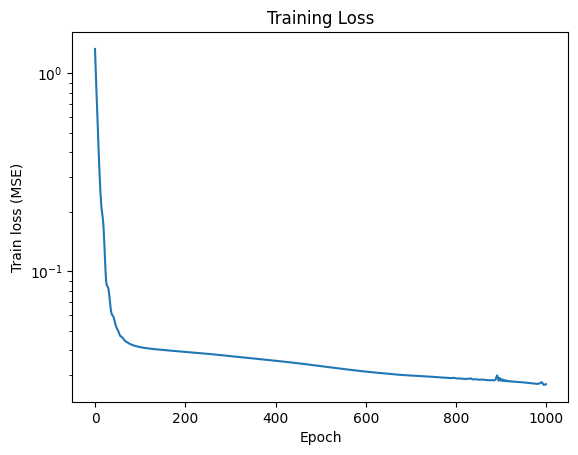

In [61]:
# Shown the Training Loss Graph

# Loss Curve
plt.plot(train_losses)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Train loss (MSE)")
plt.title("Training Loss")
plt.show()

In [65]:
# Validation loss
model.eval()
with torch.no_grad():
    train_loss = loss_fn(model(X_train_t), y_train_t).item()
    val_loss = loss_fn(model(X_val_t),y_val_t).item()

print("Train loss",train_loss)
print("Validation loss:",val_loss)

Train loss 0.026939189061522484
Validation loss: 0.0325266569852829


In [49]:
# Error in the real Value

model.eval()
with torch.no_grad():
    y_val_pred = denormalize(model(X_val_t), y_mean, y_std)
    y_val_true = denormalize(y_val_t, y_mean, y_std)

    error = (y_val_pred - y_val_true).abs()

print("average error :", error.mean().item())
print("max error :", error.max().item())


average error : 0.7640399932861328
max error : 51.302764892578125


In [66]:
# Predict vs real for the first 3 validation rows

for i in range(3):
    pred = y_val_pred[i].item()
    real = y_val_true[i].item()
    dist = X_test.iloc[i]["distance"]
    dur = X_test.iloc[i]["duration_min"]

    print(f"Trip {i+1}: {dist:.2f} mi, {dur:.1f} min | "
          f"predicted ${pred:.2f} | real ${real:.2f} | error ${abs(pred - real):.2f}")


Trip 1: 1.90 mi, 13.9 min | predicted $11.07 | real $10.50 | error $0.57
Trip 2: 0.60 mi, 4.4 min | predicted $5.14 | real $5.00 | error $0.14
Trip 3: 0.30 mi, 2.2 min | predicted $4.62 | real $3.50 | error $1.12


In [67]:
print("average error :", error.mean().item())

average error : 0.7640399932861328
